In [1]:

!pip -q install datasets sentence-transformers scikit-learn

In [2]:

import os, re, json, math, random, gc, warnings, shutil, textwrap
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import rankdata, mannwhitneyu
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_colwidth", 120)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "(no GPU: switch runtime to T4)")


RUN_EMBEDDERS      = True
RUN_CROSS_ENCODERS = True
TRAIN_ON_ABLATED   = True
RUN_LLM            = True
RESUME             = True

SEEDS   = [13, 42, 2024]
N_RAND  = 5
N_BOOT  = 2000
OUT, FIG = "outputs/results", "outputs/figures"
os.makedirs(f"{OUT}/preds", exist_ok=True); os.makedirs(FIG, exist_ok=True)


PAPER = {"best fine-tuned (TimeLM-large)": 74.64, "TimeLM-base CE": 72.24, "RoBERTa-base CE": 74.42,
         "FlanT5-XL zero-shot": 59.46, "FlanT5-XXL few-shot": 61.69}

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

device: cuda Tesla T4


In [3]:
from datasets import load_dataset

def _hf_parquet(split):
    return pd.read_parquet("hf://datasets/cardiffnlp/super_tweeteval@refs%2Fconvert%2Fparquet/"
                           f"tweet_similarity/{split}/0000.parquet")

def load_tweetsim():
    for kw in [dict(), dict(revision="refs/convert/parquet")]:
        try:
            ds = load_dataset("cardiffnlp/super_tweeteval", "tweet_similarity", **kw)
            return {k: ds[k].to_pandas() for k in ds}
        except Exception as e:
            print(f"load_dataset{kw} failed: {type(e).__name__}: {str(e)[:150]}")
    try:
        return {s: _hf_parquet(s) for s in ["train", "validation", "test"]}
    except Exception as e:
        print(f"parquet path failed: {type(e).__name__}: {str(e)[:150]}")
    try:   # last resort: find whatever data files the repo has for this subset
        from huggingface_hub import HfFileSystem
        fs, out = HfFileSystem(), {}
        pats = ["datasets/cardiffnlp/super_tweeteval@refs%2Fconvert%2Fparquet/tweet_similarity/**/*.parquet",
                "datasets/cardiffnlp/super_tweeteval/**/tweet_similarity/**/*.json*",
                "datasets/cardiffnlp/super_tweeteval/**/tweet_similarity*"]
        for pat in pats:
            for f in fs.glob(pat):
                low = f.lower(); split = ("validation" if ("valid" in low or "dev" in low) else
                                          "train" if "train" in low else "test" if "test" in low else None)
                if split and split not in out:
                    out[split] = (pd.read_parquet(f"hf://{f}") if low.endswith(".parquet")
                                  else pd.read_json(f"hf://{f}", lines=True))
            if len(out) == 3: return out
    except Exception as e:
        print(f"glob fallback failed: {type(e).__name__}: {str(e)[:150]}")
    if True:
        raise RuntimeError("Could not download TweetSim. Download the train/validation/test files of the "
                           "'tweet_similarity' subset from huggingface.co/datasets/cardiffnlp/super_tweeteval, "
                           "upload them to Colab and read them with pandas.")

def standardise(df):
    cols = list(df.columns)
    txt = [c for c in cols if df[c].dtype == object and isinstance(df[c].iloc[0], str)]
    num = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    t1 = "text_1" if "text_1" in cols else txt[0]
    t2 = "text_2" if "text_2" in cols else txt[1]
    y  = "gold_score" if "gold_score" in cols else num[0]
    return pd.DataFrame({"t1": df[t1].astype(str), "t2": df[t2].astype(str), "y": df[y].astype(float)})

raw = load_tweetsim()
print("raw columns:", list(raw["test"].columns))
data = {k: standardise(v).reset_index(drop=True) for k, v in raw.items()}
train, val, test = data["train"], data["validation"], data["test"]
print({k: len(v) for k, v in data.items()}, "| expected 450 / 100 / 450")
print("score range:", test.y.min(), "-", test.y.max())
test.head(5)

README.md:   0%|          | 0.00/30.2k [00:00<?, ?B/s]

data/tweet_similarity/train.jsonl: reconstructing file:   0%|          |  0.00B /  121kB            

data/tweet_similarity/train.jsonl: downloading bytes:           |  0.00B            

data/tweet_similarity/test.jsonl: reconstructing file:   0%|          |  0.00B /  118kB            

data/tweet_similarity/test.jsonl: downloading bytes:           |  0.00B            

...

Generating train split:   0%|          | 0/450 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/450 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/100 [00:00<?, ? examples/s]

raw columns: ['text_1', 'text_2', 'gold_score']
{'train': 450, 'test': 450, 'validation': 100} | expected 450 / 100 / 450
score range: 0.0 - 5.0


,t1,t2,y
0,India is With @republic #ImmortalSushant #FreeAnujNow #CantBlockRepublic #Nation_With_R_Bharat,Trending On 5 Number Retweet And Comment For 1st #Nation_With_R_Bharat,2.33
1,Day 18 Create an emergency music playlist for times when you need some love and comfort. #mentalhealth,On PTO today to run errands and recharge. Anyone else schedule a random PTO day? #HRcommunity #mentalhealth,1.67
2,Not diss her in a song 😂😂 #LHHATL,Who the hell hires their children for a new business???? 😂😂😂 none of them have any damn experience #LHHATL,2.33
3,Emman Manalo QUEEN JONA is heart JONABirthdayTreat onASAP HAPPY BIRTHDAY QueenJONA #HappyBirthdayJONA,"Don’t wear Brand, Be a Brand. HAPPY BIRTHDAY QueenJONA JONABirthdayTreat onASAP #HappyBirthdayJONA",3.00
4,Why the HOOT is Brendan calling out Deandra???? #BachelorInParadise,there was so much to digest in the new episode holy shit #HSMTMTS,1.33


In [4]:
TAG_RE = re.compile(r"#\w+", flags=re.UNICODE)
PROTECTED = {"@user", "{url}"}

def tags(t):            return [m.lower() for m in TAG_RE.findall(t)]
def shared_tags(a, b):  return set(tags(a)) & set(tags(b))
def n_tag_hits(t, which): return sum(1 for m in TAG_RE.findall(t) if m.lower() in which)

def remove_tags(t, which=None):
    # which=None removes every hashtag; otherwise only hashtags whose lowercase form is in `which`
    out = TAG_RE.sub(lambda m: "" if (which is None or m.group(0).lower() in which) else m.group(0), t)
    return re.sub(r"\s+", " ", out).strip()

def delete_random_words(t, n, rng):
    toks = t.split()
    elig = [i for i, w in enumerate(toks) if not w.startswith("#") and w.lower() not in PROTECTED]
    if n <= 0 or not elig:
        return t
    drop = set(rng.choice(elig, size=min(n, len(elig)), replace=False).tolist())
    return " ".join(w for i, w in enumerate(toks) if i not in drop)

def build_conditions(df, n_rand=N_RAND):
    A, B = df.t1.tolist(), df.t2.tolist()
    sh = [shared_tags(a, b) for a, b in zip(A, B)]
    conds = {"original": (A, B),
             "no_shared_tags": ([remove_tags(a, s) for a, s in zip(A, sh)], [remove_tags(b, s) for b, s in zip(B, sh)]),
             "no_tags": ([remove_tags(a) for a in A], [remove_tags(b) for b in B])}
    for k in range(n_rand):
        rng = np.random.default_rng(1000 + k)
        conds[f"rand_del_{k}"] = ([delete_random_words(a, n_tag_hits(a, s), rng) for a, s in zip(A, sh)],
                                  [delete_random_words(b, n_tag_hits(b, s), rng) for b, s in zip(B, sh)])
    return conds

test_conds  = build_conditions(test)
train_conds = build_conditions(train, n_rand=0)
val_conds   = build_conditions(val, n_rand=0)

i = next(j for j, (a, b) in enumerate(zip(test.t1, test.t2)) if shared_tags(a, b))
for c in ["original", "no_shared_tags", "rand_del_0"]:
    print(f"{c:15s} | {test_conds[c][0][i]}\n{'':15s} | {test_conds[c][1][i]}")
for c in ["no_shared_tags", "no_tags"]:
    empt = sum((a == "") or (b == "") for a, b in zip(*test_conds[c]))
    print(f"{c}: {empt} pairs have an empty tweet after deletion")

original        | India is With @republic #ImmortalSushant #FreeAnujNow #CantBlockRepublic #Nation_With_R_Bharat
                | Trending On 5 Number Retweet And Comment For 1st #Nation_With_R_Bharat
no_shared_tags  | India is With @republic #ImmortalSushant #FreeAnujNow #CantBlockRepublic
                | Trending On 5 Number Retweet And Comment For 1st
rand_del_0      | is With @republic #ImmortalSushant #FreeAnujNow #CantBlockRepublic #Nation_With_R_Bharat
                | Trending 5 Number Retweet And Comment For 1st #Nation_With_R_Bharat
no_shared_tags: 0 pairs have an empty tweet after deletion
no_tags: 0 pairs have an empty tweet after deletion


In [5]:
def describe(df, name):
    t1n = df.t1.map(lambda t: len(tags(t)) > 0); t2n = df.t2.map(lambda t: len(tags(t)) > 0)
    sh = np.array([len(shared_tags(a, b)) > 0 for a, b in zip(df.t1, df.t2)])
    y = df.y.values
    ss_tot = ((y - y.mean())**2).sum()
    ss_between = sum(m.sum() * (y[m].mean() - y.mean())**2 for m in [sh, ~sh] if m.any())
    return sh, dict(split=name, pairs=len(df), tweets_with_hashtag=f"{(t1n.mean()+t2n.mean())/2:.0%}",
                    pairs_sharing_hashtag=int(sh.sum()), share_rate=f"{sh.mean():.0%}",
                    gold_mean_shared=round(y[sh].mean(), 2) if sh.any() else None,
                    gold_mean_not_shared=round(y[~sh].mean(), 2) if (~sh).any() else None,
                    eta_sq=round(ss_between / ss_tot, 3))

SHARED, d_test = describe(test, "test")
_, d_train = describe(train, "train")
diag = pd.DataFrame([d_train, d_test]); display(diag)

Y = test.y.values
if SHARED.any() and (~SHARED).any():
    u = mannwhitneyu(Y[SHARED], Y[~SHARED], alternative="greater")
    print(f"Mann-Whitney U (shared > not shared): p = {u.pvalue:.2e}")
print(f"eta^2 = share of gold-score variance explained by 'shares a hashtag': {d_test['eta_sq']:.1%}")

rate = SHARED.mean()
if rate < 0.3 or rate > 0.97:
    print("\nWARNING: share rate is extreme, so the shortcut story is weak. Consider the backup research question.")
else:
    print(f"\nGO: {rate:.0%} of test pairs share a hashtag, so the shortcut analysis is meaningful.")

,split,pairs,tweets_with_hashtag,pairs_sharing_hashtag,share_rate,gold_mean_shared,gold_mean_not_shared,eta_sq
0,train,450,100%,372,83%,2.56,0.29,0.617
1,test,450,100%,355,79%,2.54,0.30,0.637


Mann-Whitney U (shared > not shared): p = 3.86e-51
eta^2 = share of gold-score variance explained by 'shares a hashtag': 63.7%

GO: 79% of test pairs share a hashtag, so the shortcut analysis is meaningful.


In [6]:

def spearman_rows(P, Yb):
    rp = rankdata(P, axis=1); ry = rankdata(Yb, axis=1)
    rp -= rp.mean(1, keepdims=True); ry -= ry.mean(1, keepdims=True)
    with np.errstate(invalid="ignore", divide="ignore"):
        return (rp * ry).sum(1) / np.sqrt((rp**2).sum(1) * (ry**2).sum(1))

def spearman(p, y):
    return float(spearman_rows(np.asarray(p, float)[None], np.asarray(y, float)[None])[0]) * 100

SUBSETS = {"all": np.arange(len(Y)), "shared": np.where(SHARED)[0], "not_shared": np.where(~SHARED)[0]}
_rng = np.random.default_rng(0)
BOOT = {k: _rng.integers(0, len(ix), (N_BOOT, len(ix))) for k, ix in SUBSETS.items()}

def score(pred_rows, sub):

    ix = SUBSETS[sub]; y = Y[ix]; b = BOOT[sub]
    point = np.nanmean([spearman(p[ix], y) for p in pred_rows])
    draws = np.nanmean([spearman_rows(p[ix][b], y[b]) for p in pred_rows], axis=0) * 100
    return point, draws

def ci(draws):
    d = draws[np.isfinite(draws)]
    return (np.nan, np.nan) if len(d) == 0 else tuple(np.percentile(d, [2.5, 97.5]))

print("shared-hashtag indicator alone: Spearman =", round(spearman(SHARED.astype(float), Y), 1),
      f"(paper's best fine-tuned model: {PAPER['best fine-tuned (TimeLM-large)']})")

shared-hashtag indicator alone: Spearman = 70.8 (paper's best fine-tuned model: 74.64)


In [7]:
SYSTEMS = {}

def slug(s): return re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")

def register(name, family, preds):
    preds = {c: np.atleast_2d(np.asarray(v, float)) for c, v in preds.items()}
    SYSTEMS[name] = dict(family=family, preds=preds)
    np.savez(f"{OUT}/preds/{slug(name)}.npz", **preds)
    json.dump({"name": name, "family": family}, open(f"{OUT}/preds/{slug(name)}.json", "w"))
    print(f"registered {name:45s} original/all Spearman = {spearman(preds['original'].mean(0), Y):5.1f}")

def cached(name):
    p = f"{OUT}/preds/{slug(name)}.npz"
    if RESUME and os.path.exists(p):
        meta = json.load(open(p.replace(".npz", ".json")))
        SYSTEMS[name] = dict(family=meta["family"], preds=dict(np.load(p)))
        print("cached:", name); return True
    return False

def free():
    gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

In [8]:
# 5a. Surface baselines: no learning, no semantics
from sklearn.feature_extraction.text import TfidfVectorizer

def jacc(a, b):
    a, b = set(a), set(b); return len(a & b) / len(a | b) if (a | b) else 0.0
def words(t): return re.findall(r"[#@]?\w+", t.lower())

tfidf = TfidfVectorizer(token_pattern=r"[#@]?\w+", sublinear_tf=True).fit(pd.concat([train.t1, train.t2]))
def tfidf_cos(A, B):
    return np.asarray(tfidf.transform(A).multiply(tfidf.transform(B)).sum(1)).ravel()

BASELINES = {
    "Shared-hashtag indicator": lambda A, B: [float(len(shared_tags(a, b)) > 0) for a, b in zip(A, B)],
    "Hashtag Jaccard":          lambda A, B: [jacc(tags(a), tags(b)) for a, b in zip(A, B)],
    "Word Jaccard":             lambda A, B: [jacc(words(a), words(b)) for a, b in zip(A, B)],
    "TF-IDF cosine":            tfidf_cos,
}
for name, f in BASELINES.items():
    register(name, "Surface baseline", {c: f(A, B) for c, (A, B) in test_conds.items()})

registered Shared-hashtag indicator                      original/all Spearman =  70.8
registered Hashtag Jaccard                               original/all Spearman =  60.1
registered Word Jaccard                                  original/all Spearman =  56.1
registered TF-IDF cosine                                 original/all Spearman =  38.8


In [9]:

EMBEDDERS = [
    # (display name, HF model id, input prefix, family)
    ("MiniLM-L6",           "sentence-transformers/all-MiniLM-L6-v2",           "",        "Zero-shot embedder (general)"),
    ("MPNet-base",          "sentence-transformers/all-mpnet-base-v2",          "",        "Zero-shot embedder (general)"),
    ("BGE-base",            "BAAI/bge-base-en-v1.5",                            "",        "Zero-shot embedder (general)"),
    ("E5-base",             "intfloat/e5-base-v2",                              "query: ", "Zero-shot embedder (general)"),
    ("Tweet-RoBERTa emb.",  "cambridgeltl/tweet-roberta-base-embeddings-v1",    "",        "Zero-shot embedder (Twitter)"),
    ("TimeLM-base mean-pool", "cardiffnlp/twitter-roberta-base-2022-154m",      "",        "Zero-shot embedder (Twitter)"),
]

if RUN_EMBEDDERS:
    from sentence_transformers import SentenceTransformer
    uniq = sorted({t for A, B in test_conds.values() for t in A + B})
    pos = {t: i for i, t in enumerate(uniq)}
    for name, mid, prefix, fam in EMBEDDERS:
        if cached(name): continue
        try:
            m = SentenceTransformer(mid, device=DEVICE)
            E = m.encode([prefix + t for t in uniq], batch_size=64, normalize_embeddings=True,
                         convert_to_numpy=True, show_progress_bar=False)
            preds = {c: (E[[pos[t] for t in A]] * E[[pos[t] for t in B]]).sum(1) for c, (A, B) in test_conds.items()}
            register(name, fam, preds)
        except Exception as e:
            print(f"SKIPPED {name}: {type(e).__name__}: {str(e)[:200]}")
        finally:
            m = None; free()

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

registered TimeLM-base mean-pool                         original/all Spearman =  56.7


In [10]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

CE_MODELS = [("TimeLM-base CE",  "cardiffnlp/twitter-roberta-base-2022-154m"),
             ("RoBERTa-base CE", "roberta-base")]
CFG = dict(lr=2e-5, bs=16, epochs=10, max_len=128, warmup=0.1, wd=0.01)
AMP = DEVICE == "cuda"

def ce_predict(model, tok, A, B, bs=64):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(A), bs):
            enc = tok(A[i:i+bs], B[i:i+bs], truncation=True, max_length=CFG["max_len"],
                      padding=True, return_tensors="pt").to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                out.append(model(**enc).logits.squeeze(-1).float().cpu().numpy())
    return np.concatenate(out) * 5.0

def train_ce(mid, seed, tr, va, yv):
    set_seed(seed)
    tok = AutoTokenizer.from_pretrained(mid)
    model = AutoModelForSequenceClassification.from_pretrained(mid, num_labels=1).to(DEVICE)
    (A, B), y = tr, torch.tensor(train.y.values / 5.0, dtype=torch.float32)
    n, bs = len(A), CFG["bs"]; total = math.ceil(n / bs) * CFG["epochs"]
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["wd"])
    sch = get_linear_schedule_with_warmup(opt, int(CFG["warmup"] * total), total)
    try:    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    except Exception: scaler = torch.cuda.amp.GradScaler(enabled=AMP)
    g, best, best_state, best_ep = np.random.default_rng(seed), -1e9, None, -1
    for ep in range(CFG["epochs"]):
        model.train(); perm = g.permutation(n)
        for i in range(0, n, bs):
            b = perm[i:i+bs]
            enc = tok([A[j] for j in b], [B[j] for j in b], truncation=True, max_length=CFG["max_len"],
                      padding=True, return_tensors="pt").to(DEVICE)
            with torch.autocast("cuda", dtype=torch.float16, enabled=AMP):
                logits = model(**enc).logits.squeeze(-1)
            loss = torch.nn.functional.mse_loss(logits.float(), y[torch.as_tensor(b)].to(DEVICE))
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sch.step()
        vs = spearman(ce_predict(model, tok, *va), yv)
        if vs > best:
            best, best_ep = vs, ep
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, tok, best, best_ep

SEED_LOG = []
if RUN_CROSS_ENCODERS:
    settings = [("original", "")] + ([("no_tags", " (trained w/o hashtags)")] if TRAIN_ON_ABLATED else [])
    for base, mid in CE_MODELS:
        for tr_cond, suffix in settings:
            name = base + suffix
            if cached(name): continue
            preds = {c: [] for c in test_conds}
            for seed in SEEDS:
                model, tok, vbest, ep = train_ce(mid, seed, train_conds[tr_cond], val_conds[tr_cond], val.y.values)
                for c, (A, B) in test_conds.items():
                    preds[c].append(ce_predict(model, tok, A, B))
                SEED_LOG.append(dict(system=name, seed=seed, dev_spearman=round(vbest, 2), best_epoch=ep + 1,
                                     test_original=round(spearman(preds["original"][-1], Y), 2),
                                     test_no_shared_tags=round(spearman(preds["no_shared_tags"][-1], Y), 2)))
                print(SEED_LOG[-1]); model = None; free()
            register(name, "Fine-tuned cross-encoder", {c: np.vstack(v) for c, v in preds.items()})
    if SEED_LOG:
        pd.DataFrame(SEED_LOG).to_csv(f"{OUT}/cross_encoder_seeds.csv", index=False)
        display(pd.DataFrame(SEED_LOG).groupby("system")[["test_original", "test_no_shared_tags"]].agg(["mean", "std"]).round(2))
    print("paper:", {k: v for k, v in PAPER.items() if "CE" in k})

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-2022-154m
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'system': 'TimeLM-base CE', 'seed': 13, 'dev_spearman': 77.94, 'best_epoch': 6, 'test_original': 73.85, 'test_no_shared_tags': 47.62}


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-2022-154m
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


...

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'system': 'RoBERTa-base CE (trained w/o hashtags)', 'seed': 2024, 'dev_spearman': 34.65, 'best_epoch': 10, 'test_original': 59.67, 'test_no_shared_tags': 37.81}
registered RoBERTa-base CE (trained w/o hashtags)        original/all Spearman =  66.0


test_original       test_no_shared_tags      
                                                mean   std                mean   std
system                                                                              
RoBERTa-base CE                                74.71  1.69               57.41  2.88
RoBERTa-base CE (trained w/o hashtags)         63.43  3.27               43.63  5.63
TimeLM-base CE                                 74.75  0.88               54.40  5.88
TimeLM-base CE (trained w/o hashtags)          62.26  2.65               47.73  3.62

paper: {'TimeLM-base CE': 72.24, 'RoBERTa-base CE': 74.42}


In [11]:
LLM_ID = "Qwen/Qwen2.5-1.5B-Instruct"
SCALE = ("5 = equivalent (same situation, minor details may differ)\n"
         "4 = almost equivalent (same situation/event/person, some relevant differences)\n"
         "3 = not equivalent but share details about a similar situation/event/person\n"
         "2 = categorically related (same topic or category, e.g. sports, politics)\n"
         "1 = loosely related (something minor in common)\n"
         "0 = no relation")

def llm_messages(a, b):
    return [{"role": "system", "content": "You are a careful annotator of tweets."},
            {"role": "user", "content": f"How similar are these two tweets?\n{SCALE}\n\nTweet 1: {a}\nTweet 2: {b}\n\n"
                                        "Answer with a single digit from 0 to 5."}]

def run_llm(dtype):
    tok = AutoTokenizer.from_pretrained(LLM_ID); tok.padding_side = "left"
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(LLM_ID, torch_dtype=dtype).to(DEVICE).eval()
    digit_ids = [tok.encode(str(d), add_special_tokens=False) for d in range(6)]
    assert all(len(x) == 1 for x in digit_ids), digit_ids
    digit_ids = [x[0] for x in digit_ids]; vals = torch.arange(6, dtype=torch.float32)
    preds = {}
    for c, (A, B) in test_conds.items():
        prompts = [tok.apply_chat_template(llm_messages(a, b), tokenize=False, add_generation_prompt=True) for a, b in zip(A, B)]
        out = []
        for i in range(0, len(prompts), 16):
            enc = tok(prompts[i:i+16], return_tensors="pt", padding=True).to(DEVICE)
            with torch.no_grad():
                logits = model(**enc).logits[:, -1, :].float()
            p = torch.softmax(logits[:, digit_ids], dim=-1).cpu()
            if not torch.isfinite(p).all(): raise FloatingPointError("non-finite probabilities")
            out.append((p * vals).sum(-1).numpy())
        preds[c] = np.concatenate(out)
    del model; free()
    return preds

if RUN_LLM and not cached("Qwen2.5-1.5B (zero-shot)"):
    from transformers import AutoModelForCausalLM
    try:
        try:    preds = run_llm(torch.float16 if DEVICE == "cuda" else torch.float32)
        except FloatingPointError:
            print("fp16 overflow, retrying in fp32"); preds = run_llm(torch.float32)
        register("Qwen2.5-1.5B (zero-shot)", "Zero-shot LLM", preds)
    except Exception as e:
        print(f"SKIPPED LLM: {type(e).__name__}: {str(e)[:200]}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

registered Qwen2.5-1.5B (zero-shot)                      original/all Spearman =  62.0


In [12]:

for p in sorted(os.listdir(f"{OUT}/preds")):
    if p.endswith(".json"):
        meta = json.load(open(f"{OUT}/preds/{p}"))
        if meta["name"] not in SYSTEMS: cached(meta["name"])

def rows_for(name, s):
    P = s["preds"]
    rand = np.vstack([P[c] for c in P if c.startswith("rand_del_")])
    views = {"original": P["original"], "no_shared_tags": P["no_shared_tags"], "no_tags": P["no_tags"], "rand_del": rand}
    long, wide = [], dict(system=name, family=s["family"])
    for sub in SUBSETS:
        draws = {}
        for cond, rows in views.items():
            pt, d = score(rows, sub); draws[cond] = (pt, d); lo, hi = ci(d)
            long.append(dict(system=name, family=s["family"], subset=sub, condition=cond,
                             spearman=pt, ci_lo=lo, ci_hi=hi, n=len(SUBSETS[sub])))
        if sub == "not_shared": continue          # nothing is deleted in these pairs
        for lab, a, b in [("drop_tags", "original", "no_shared_tags"), ("drop_random", "original", "rand_del"),
                          ("excess_drop", "rand_del", "no_shared_tags")]:
            pt = draws[a][0] - draws[b][0]; lo, hi = ci(draws[a][1] - draws[b][1])
            long.append(dict(system=name, family=s["family"], subset=sub, condition=lab,
                             spearman=pt, ci_lo=lo, ci_hi=hi, n=len(SUBSETS[sub])))
    return long

R = pd.DataFrame([r for n, s in SYSTEMS.items() for r in rows_for(n, s)])
R.to_csv(f"{OUT}/all_results_long.csv", index=False)

def fmt(sub, cond):
    q = R[(R.subset == sub) & (R.condition == cond)].set_index("system")
    return q.apply(lambda r: f"{r.spearman:5.1f} [{r.ci_lo:5.1f}, {r.ci_hi:5.1f}]" if np.isfinite(r.spearman) else "n/a", axis=1)

FAM_ORDER = ["Surface baseline", "Zero-shot embedder (general)", "Zero-shot embedder (Twitter)",
             "Zero-shot LLM", "Fine-tuned cross-encoder"]
T = pd.DataFrame({"family": R.drop_duplicates("system").set_index("system").family,
                  "rho_all": fmt("all", "original"), "rho_shared": fmt("shared", "original"),
                  "rho_not_shared": fmt("not_shared", "original"),
                  "drop_tags": fmt("all", "drop_tags"), "drop_random": fmt("all", "drop_random"),
                  "excess_drop": fmt("all", "excess_drop"), "excess_drop_shared": fmt("shared", "excess_drop")})
T["_f"] = T.family.map(FAM_ORDER.index); T = T.sort_values(["_f"]).drop(columns="_f")
T.to_csv(f"{OUT}/summary_table.csv"); display(T)

,family,rho_all,rho_shared,rho_not_shared,drop_tags,drop_random,excess_drop,excess_drop_shared
system,,,,,,,,
Shared-hashtag indicator,Surface baseline,"70.8 [ 65.8, 74.8]",n/a,n/a,n/a,"0.0 [ 0.0, 0.0]",n/a,n/a
Hashtag Jaccard,Surface baseline,"60.1 [ 52.3, 67.1]","6.8 [ -4.1, 17.0]",n/a,n/a,"0.0 [ 0.0, 0.0]",n/a,n/a
Word Jaccard,Surface baseline,"56.1 [ 48.8, 62.7]","31.8 [ 21.7, 41.7]","10.9 [ -8.1, 30.4]","19.8 [ 15.2, 24.1]","0.2 [ -0.8, 1.2]","19.6 [ 14.5, 24.4]","-1.0 [ -5.4, 3.4]"
TF-IDF cosine,Surface baseline,"38.8 [ 30.5, 46.6]","28.5 [ 18.5, 38.1]","2.0 [-16.5, 21.6]","6.1 [ 1.8, 10.1]","3.8 [ 2.1, 5.9]","2.3 [ -2.5, 7.0]","-4.9 [-11.3, 1.8]"
MiniLM-L6,Zero-shot embedder (general),"70.9 [ 64.6, 76.0]","45.6 [ 36.1, 54.4]","33.7 [ 13.5, 52.4]","15.2 [ 9.4, 21.2]","1.3 [ 0.3, 2.4]","13.9 [ 7.6, 20.3]","-5.7 [-13.5, 2.1]"
MPNet-base,Zero-shot embedder (general),"73.0 [ 67.2, 77.9]","50.7 [ 41.8, 58.8]","36.7 [ 16.4, 54.6]","15.7 [ 10.2, 21.2]","1.9 [ 1.0, 3.0]","13.7 [ 7.7, 19.6]","-7.2 [-13.7, -0.4]"
BGE-base,Zero-shot embedder (general),"70.3 [ 64.5, 75.6]","49.6 [ 40.6, 57.8]","37.7 [ 18.8, 53.3]","22.1 [ 16.8, 27.7]","2.1 [ 1.0, 3.2]","20.0 [ 14.1, 25.8]","-1.7 [ -7.9, 4.6]"
E5-base,Zero-shot embedder (general),"75.9 [ 70.4, 80.6]","53.7 [ 45.0, 61.6]","41.5 [ 23.1, 56.8]","21.3 [ 15.5, 27.3]","1.7 [ 0.9, 2.6]","19.6 [ 13.5, 26.0]","-0.1 [ -7.3, 7.1]"
Tweet-RoBERTa emb.,Zero-shot embedder (Twitter),"73.7 [ 67.9, 78.8]","48.4 [ 38.5, 57.1]","40.7 [ 20.7, 57.4]","9.6 [ 4.5, 14.8]","1.0 [ 0.2, 1.8]","8.6 [ 3.4, 13.9]","-0.9 [ -9.1, 7.2]"


In [13]:

def val(sys, sub, cond):
    q = R[(R.system == sys) & (R.subset == sub) & (R.condition == cond)].spearman
    return q.iloc[0] if len(q) else np.nan
P_T = pd.DataFrame([dict(System=s, Family=SYSTEMS[s]["family"],
                         **{"ρ all": val(s, "all", "original"), "ρ shared-hashtag pairs": val(s, "shared", "original"),
                            "Δ hashtags removed": val(s, "all", "drop_tags"), "Δ random words removed": val(s, "all", "drop_random")})
                    for s in SYSTEMS]).round(1)
P_T["_f"] = P_T.Family.map(FAM_ORDER.index); P_T = P_T.sort_values(["_f", "ρ all"]).drop(columns="_f")
P_T.to_csv(f"{OUT}/poster_table.csv", index=False)
print(P_T.to_markdown(index=False))

| System                                 | Family                       |   ρ all |   ρ shared-hashtag pairs |   Δ hashtags removed |   Δ random words removed |
|:---------------------------------------|:-----------------------------|--------:|-------------------------:|---------------------:|-------------------------:|
| TF-IDF cosine                          | Surface baseline             |    38.8 |                     28.5 |                  6.1 |                      3.8 |
| Word Jaccard                           | Surface baseline             |    56.1 |                     31.8 |                 19.8 |                      0.2 |
| Hashtag Jaccard                        | Surface baseline             |    60.1 |                      6.8 |                nan   |                      0   |
| Shared-hashtag indicator               | Surface baseline             |    70.8 |                    nan   |                nan   |                      0   |
| BGE-base                        

In [14]:
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#9a9893", "#e4e3df"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({"font.size": 15, "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "axes.grid.axis": "x", "grid.color": GRID, "grid.linewidth": 1,
                     "figure.facecolor": "white", "axes.facecolor": "white", "svg.fonttype": "none"})

def save(fig, name):
    for ext in ["png", "svg", "pdf"]:
        fig.savefig(f"{FIG}/{name}.{ext}", dpi=300, bbox_inches="tight")
    plt.show()

def row_layout(systems_by_family):
    rows = []
    for fam in FAM_ORDER:
        if fam in systems_by_family and systems_by_family[fam]:
            rows.append((fam, True)); rows += [(s, False) for s in systems_by_family[fam]]
    return rows

def draw_rows(ax, rows):
    ax.set_yticks(range(len(rows))); ax.set_yticklabels([r for r, _ in rows])
    for lab, (r, hdr) in zip(ax.get_yticklabels(), rows):
        if hdr: lab.set_fontweight("bold"); lab.set_color(INK2); lab.set_fontsize(13)
    ax.set_ylim(len(rows) - 0.4, -0.6); ax.tick_params(axis="y", length=0)

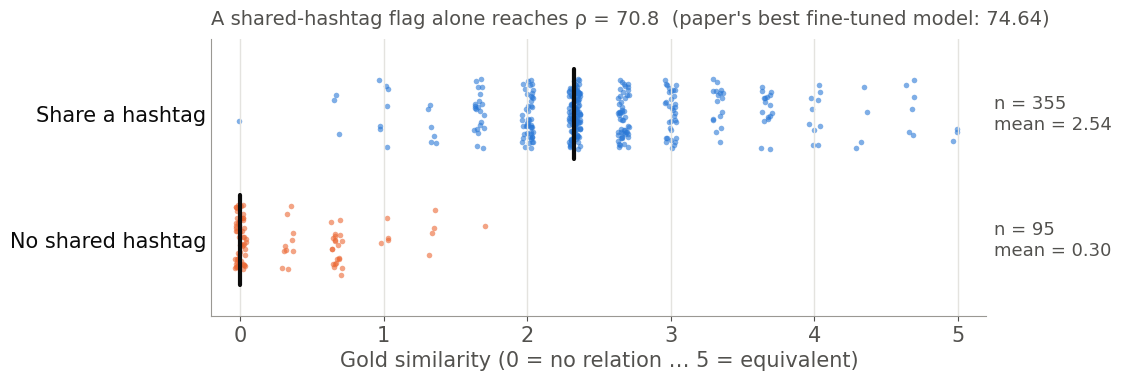

In [15]:

fig, ax = plt.subplots(figsize=(10, 3.6))
rng = np.random.default_rng(0)
groups = [("Share a hashtag", SHARED, BLUE), ("No shared hashtag", ~SHARED, ORANGE)]
for i, (lab, m, col) in enumerate(groups):
    y = Y[m]
    ax.scatter(y + rng.uniform(-0.04, 0.04, len(y)), i + rng.uniform(-0.28, 0.28, len(y)), s=16, color=col, alpha=0.6, lw=0)
    ax.plot([np.median(y)] * 2, [i - 0.36, i + 0.36], color=INK, lw=3, solid_capstyle="round")
    ax.text(5.25, i, f"n = {m.sum()}\nmean = {y.mean():.2f}", va="center", fontsize=13, color=INK2)
ax.set_yticks([0, 1]); ax.set_yticklabels([g[0] for g in groups]); ax.set_ylim(1.6, -0.6)
ax.set_xlim(-0.2, 5.2); ax.set_xlabel("Gold similarity (0 = no relation … 5 = equivalent)")
ax.tick_params(axis="y", length=0)
ax.set_title(f"A shared-hashtag flag alone reaches ρ = {spearman(SHARED.astype(float), Y):.1f}"
             f"  (paper's best fine-tuned model: {PAPER['best fine-tuned (TimeLM-large)']})",
             loc="left", fontsize=14, color=INK2, pad=10)
save(fig, "fig1_gold_by_hashtag")

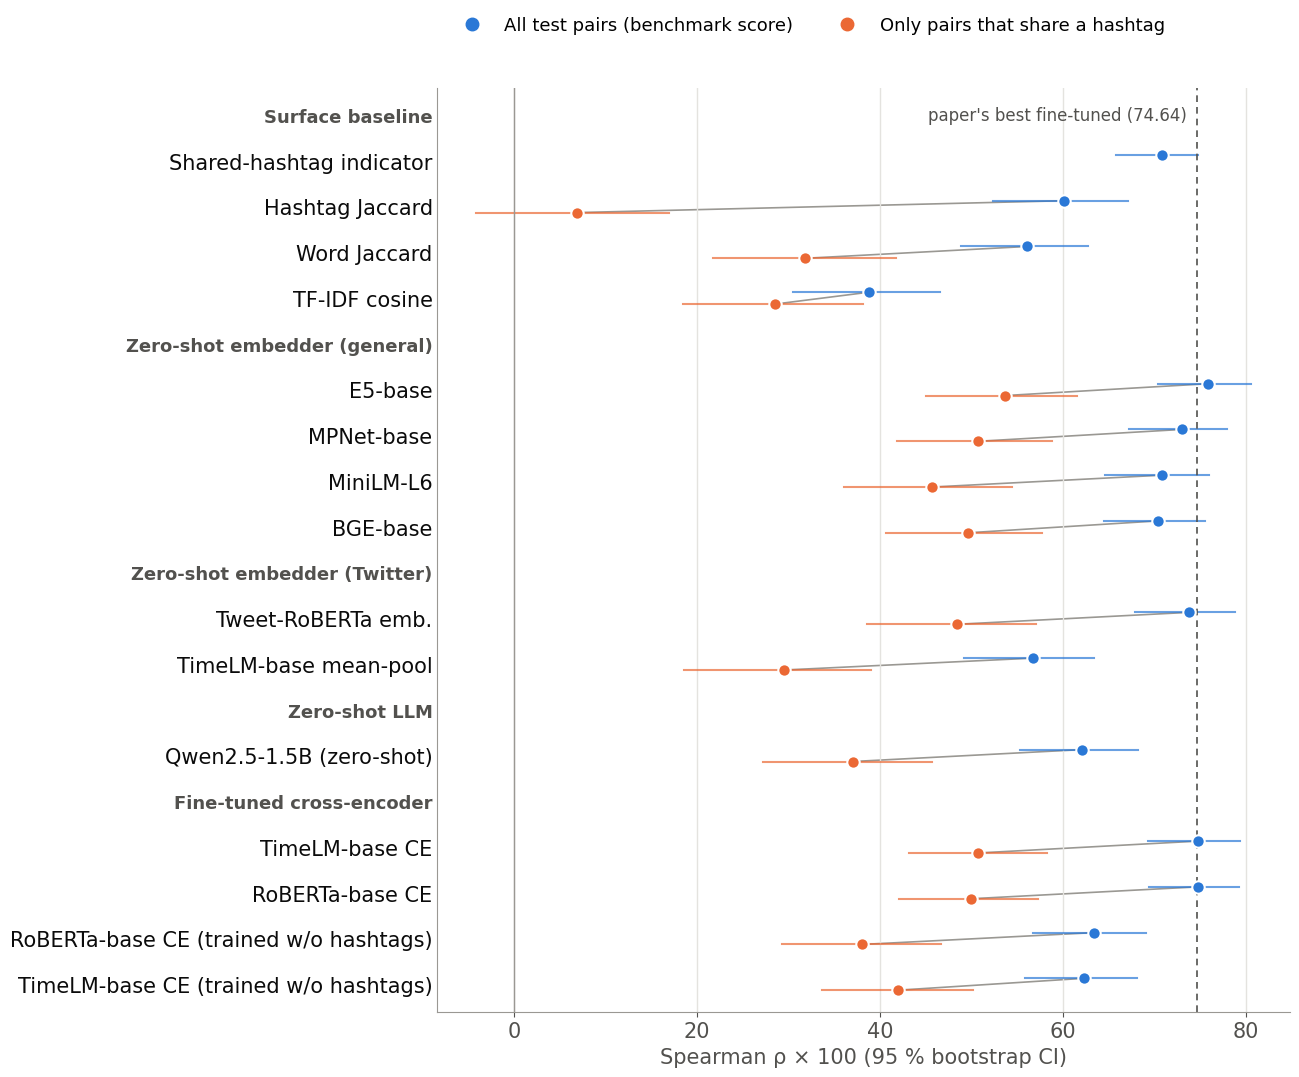

In [16]:

orig = R[R.condition == "original"]
def order(fam):
    q = orig[(orig.family == fam) & (orig.subset == "all")].sort_values("spearman", ascending=False)
    return list(q.system)
rows = row_layout({f: order(f) for f in FAM_ORDER})
fig, ax = plt.subplots(figsize=(11, 0.52 * len(rows) + 1.6))
for yi, (s, hdr) in enumerate(rows):
    if hdr: continue
    pts = []
    for sub, col, off in [("all", BLUE, -0.13), ("shared", ORANGE, 0.13)]:
        r = orig[(orig.system == s) & (orig.subset == sub)].iloc[0]
        if not np.isfinite(r.spearman): continue
        ax.plot([r.ci_lo, r.ci_hi], [yi + off] * 2, color=col, lw=1.5, alpha=0.7)
        pts.append(r.spearman)
        ax.scatter(r.spearman, yi + off, s=80, color=col, zorder=3, edgecolor="white", lw=1.5)
    if len(pts) == 2: ax.plot(pts, [yi - 0.13, yi + 0.13], color=MUTED, lw=1.2, zorder=1)
draw_rows(ax, rows)
best = PAPER["best fine-tuned (TimeLM-large)"]
ax.axvline(best, color=INK2, ls=(0, (4, 3)), lw=1.2)
ax.text(best, 0, f"paper's best fine-tuned ({best})  ", fontsize=12, color=INK2, va="center", ha="right")
ax.axvline(0, color=MUTED, lw=1)
ax.set_xlabel("Spearman ρ × 100 (95 % bootstrap CI)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, ms=9, label="All test pairs (benchmark score)"),
                   Line2D([], [], marker="o", ls="", color=ORANGE, ms=9, label="Only pairs that share a hashtag")],
          loc="lower left", bbox_to_anchor=(0, 1.04), ncol=2, frameon=False, fontsize=13)
save(fig, "fig2_all_vs_shared")

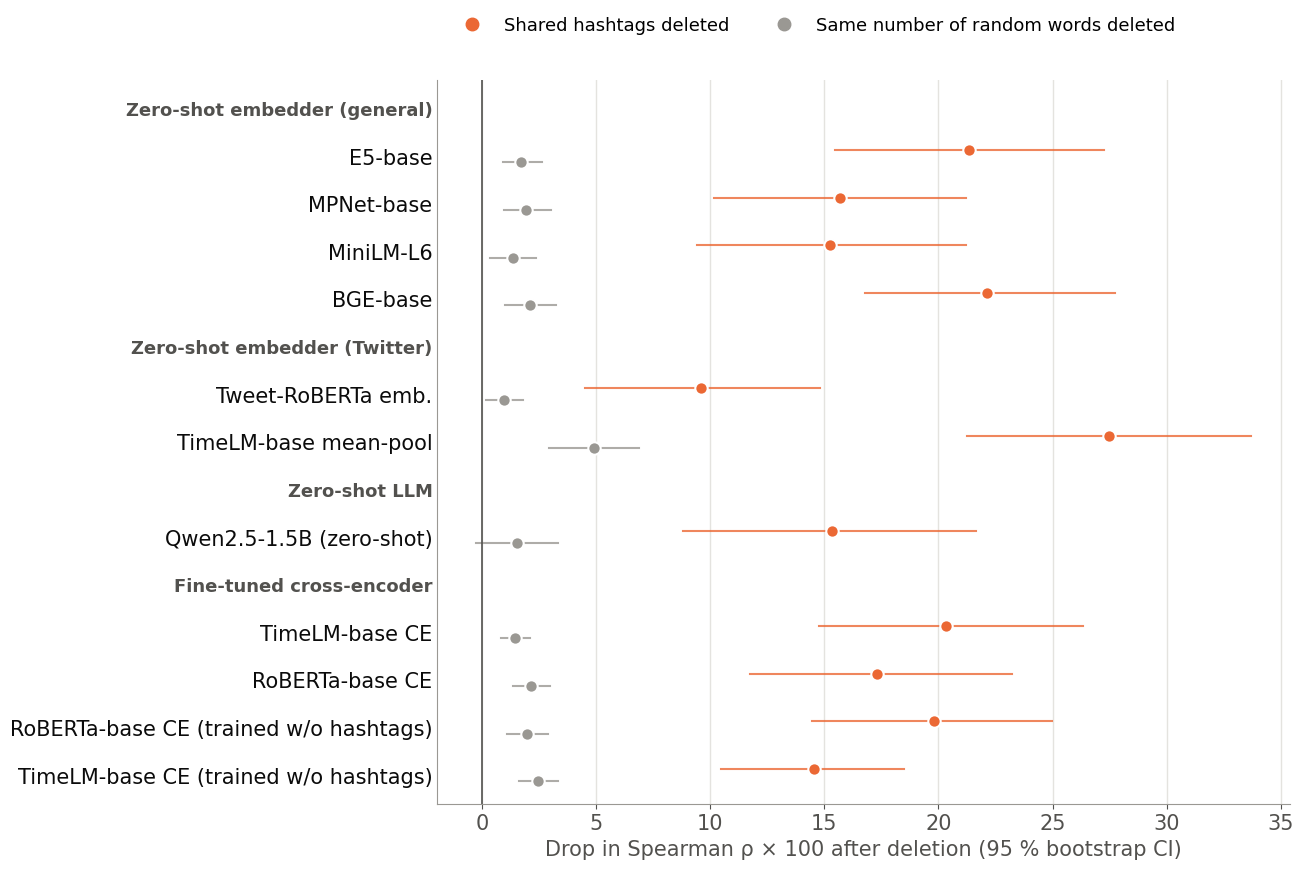

In [17]:

FIG3_SUBSET = "all"
d = R[(R.subset == FIG3_SUBSET) & R.condition.isin(["drop_tags", "drop_random"])]
fams = [f for f in FAM_ORDER if f != "Surface baseline"]
rows = row_layout({f: [s for s in order(f)] for f in fams})
fig, ax = plt.subplots(figsize=(11, 0.52 * len(rows) + 1.6))
for yi, (s, hdr) in enumerate(rows):
    if hdr: continue
    for cond, col, off in [("drop_tags", ORANGE, -0.13), ("drop_random", MUTED, 0.13)]:
        r = d[(d.system == s) & (d.condition == cond)]
        if r.empty or not np.isfinite(r.iloc[0].spearman): continue
        r = r.iloc[0]
        ax.plot([r.ci_lo, r.ci_hi], [yi + off] * 2, color=col, lw=1.5, alpha=0.8)
        ax.scatter(r.spearman, yi + off, s=80, color=col, zorder=3, edgecolor="white", lw=1.5)
draw_rows(ax, rows)
ax.axvline(0, color=INK2, lw=1.2)
ax.set_xlabel("Drop in Spearman ρ × 100 after deletion (95 % bootstrap CI)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=ORANGE, ms=9, label="Shared hashtags deleted"),
                   Line2D([], [], marker="o", ls="", color=MUTED, ms=9, label="Same number of random words deleted")],
          loc="lower left", bbox_to_anchor=(0, 1.04), ncol=2, frameon=False, fontsize=13)
save(fig, f"fig3_ablation_{FIG3_SUBSET}")

In [18]:
ex = test.assign(shared=SHARED)
print("=== Same hashtag, low gold similarity ===")
for _, r in ex[ex.shared].sort_values("y").head(5).iterrows():
    print(f"gold {r.y:.2f} | {r.t1}\n          | {r.t2}\n")

ce = next((s for s in SYSTEMS if s == "TimeLM-base CE"), None)
if ce:
    P = SYSTEMS[ce]["preds"]
    delta = P["original"].mean(0) - P["no_shared_tags"].mean(0)
    print(f"=== {ce}: largest score change when shared hashtags are deleted ===")
    for i in np.argsort(-np.abs(delta))[:5]:
        print(f"gold {Y[i]:.2f} | pred {P['original'].mean(0)[i]:.2f} -> {P['no_shared_tags'].mean(0)[i]:.2f}\n"
              f"          | {test.t1[i]}\n          | {test.t2[i]}\n")

=== Same hashtag, low gold similarity ===
gold 0.00 | I remember when Jews was walking around with Js, we should treat the unvaccinated the same. #GetVaccinated #Unvaccinated #VAXXED #antivaxxers #Joerogan #BoosterShots #mRNA #Pfizer #BidenIsADisgrace #VaccinePassports #Emmys2021 #EmmysSoWhite #Emmys
          | Julianne Nicholson acting over the play-off music until they stopped. I KNOW THAT'S RIGHT #Emmys

gold 0.67 | This is how I do things. Got it? #bot
          | he was born into a family of puppeteer that consisted of his mother, father, older brother, and younger sister. Though his family was renowned for their ability to create and control automatons #bot

gold 0.67 | The #BlackOpsColdWar Multiplayer Beta will have 6 Maps #CallOfDuty #COLDWAR #LEAKS #LEAKED
          | Subscribe & Visit the T.R.A.P #YouTube channel for more videos on #LEAKED

gold 0.67 | Preparing for oncoming quarantine by purchasing blackout curtains and a projector for my bedroom instead of water/whatever y

In [19]:

diag.to_csv(f"{OUT}/dataset_diagnostic.csv", index=False)
json.dump(dict(CFG=CFG if RUN_CROSS_ENCODERS else None, SEEDS=SEEDS, N_RAND=N_RAND, N_BOOT=N_BOOT,
               torch=torch.__version__, device=DEVICE), open(f"{OUT}/run_config.json", "w"), indent=1)
shutil.make_archive("tweetsim_outputs", "zip", "outputs")
try:
    from google.colab import files; files.download("tweetsim_outputs.zip")
except Exception:
    print("saved tweetsim_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>